## Parse frames from video

In [14]:
%%bash
mkdir -p frames
if [ -z "$( ls -A 'frames' )" ]; then
    ffmpeg -i original.mp4 -vf fps=24 frames/frame%04d.png
else
    echo Frames folder not empty, skipping
fi

Frames folder not empty, skipping


## Render parameters

In [15]:
HEIGHT = 12
WIDTH = 220
FRAMES = 5258 # 5258
FPS = 1 # 24
MODE = 3 # 1 for sequence per frame, 2 for sequence per coordinate, 3 for sequence per line
GROUP1 = 'AG'
GROUP2 = 'CT'

In [16]:
%%writefile custom.matrix
   A  C  G  T
A  2 -4  2 -4
C -4  2 -4  2
G  2 -4  2 -4
T -4  2 -4  2

Overwriting custom.matrix


## Generate `.fa` files
Be aware that this will empty the `queries` folder. In mode 3, we will also generate `.json` files to indiciate which lines each frame is composed of.

In [17]:
!mkdir -p queries
!rm queries/*.fa
!rm queries/*.json
from query_generator import *
if MODE == 1:
    generate_queries_by_frame(HEIGHT, WIDTH, FRAMES, FPS, GROUP1, GROUP2)
elif MODE == 2:
    generate_queries_by_coordinate(HEIGHT, WIDTH, FRAMES, FPS, GROUP1, GROUP2)
elif MODE == 3:
    generate_queries_by_line(HEIGHT, WIDTH, FRAMES, FPS, GROUP1, GROUP2)

Done with 1977 unique lines!                                                  


## Prepare matplotlib canvas

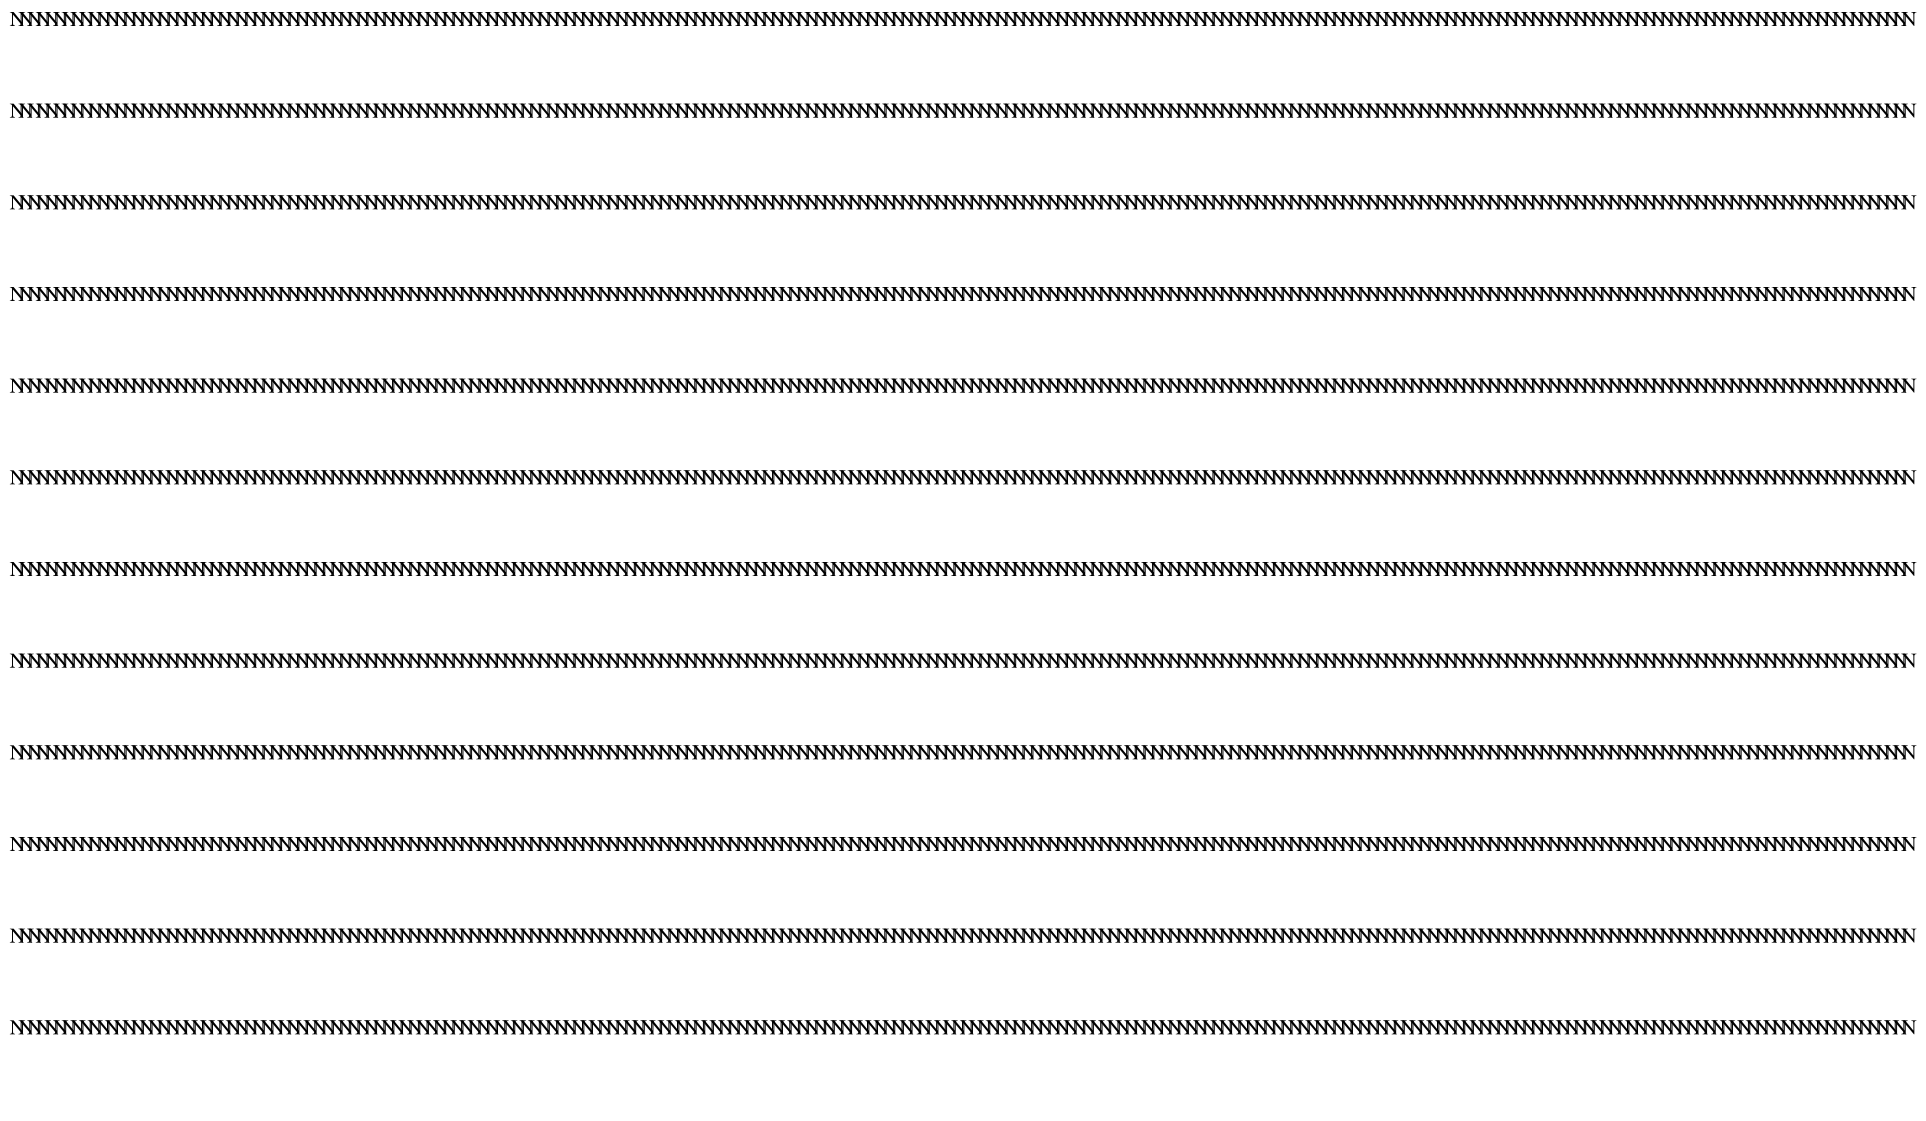

In [18]:
def get_sequence(data):
    if data["status"] != "Sequence found":
        return ""
    s = data["sequence"]
    if data["rev-comp"]:
        s = s[::-1].replace("A", "_").replace("T", "A").replace("_", "T").replace("C", "_").replace("G", "C").replace("_", "G")
    return s

sequences = {}

import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

plt.rcParams['font.family'] = 'STIXGeneral'

fig, ax = plt.subplots(figsize=(19, 11))
ax.axis("off")

fig_text = {}
for x in range(WIDTH):
    for y in range(HEIGHT):
        fig_text[(x, y)] = fig.text(x/WIDTH, 1-y/HEIGHT, "N", fontsize=16)
        
plt.tight_layout()
        
def clear():
    for tx in fig_text.values():
        tx.set_text("-")
        tx.set_color((0,0,0))
        
def get_color(base):
    return (1,0,0) if base in GROUP1 else (0,0,1) if base in GROUP2 else (0,0,0)

def draw(i):
    if MODE == 1:
        if sequences[i] == "":
            return
        print(f"Drawing frame {i} in frame mode", end="\r", flush=True)
        remainder = len(sequences[i]) % WIDTH
        pad_width = (WIDTH - remainder) % WIDTH
        sequence = np.pad(np.array(list(sequences[i])), (0, pad_width), mode='constant', constant_values='-').reshape((-1, WIDTH))
        for x in range(WIDTH):
            for y in range(HEIGHT):
                base = sequence[y,x]
                color = get_color(base)
                fig_text[(x, y)].set_text(base)
                fig_text[(x, y)].set_color(color)
    elif MODE == 2:
        print(f"Drawing frame {i} in coordinate mode", end="\r", flush=True)
        for x, y in fig_text.keys():
            sequence = sequences[(x, y)]
            if sequence != "":
                base = sequence[i] if i<len(sequence) else '-'
                color = get_color(base)
                fig_text[(x, y)].set_text(base)
                fig_text[(x, y)].set_color(color)
    elif MODE == 3:
        print(f"Drawing frame {i} in line mode", end="\r", flush=True)
        if i not in sequences:
              return
        sequence = np.array(list(sequences[i])).reshape((HEIGHT, WIDTH))
        for x in range(WIDTH):
            for y in range(HEIGHT):
                base = sequence[y,x]
                color = get_color(base)
                fig_text[(x, y)].set_text(base)
                fig_text[(x, y)].set_color(color)
        
                

## Sample for mode 1 (render single frame)

In [19]:
# Sample
if MODE == 1:
    sample_frame = "3217"
    !glsearch36 -s custom.matrix -b 1 -d 1 queries/query_{sample_frame}.fa chr1.fna > sample.output

In [20]:
# Sample
if MODE == 1:
    from IPython.display import Image
    Image(filename=f'frames/frame{sample_frame}.png')

In [21]:
# Sample
if MODE == 1:
    with open(f"queries/query_{sample_frame}.fa", "r") as f:
        f.readline()
        sequences[-2] = f.readline()
    draw(-2)
    sequences.pop(-2)
    fig

In [22]:
if MODE == 1:
    clear()

In [23]:
# Sample
if MODE == 1:
    from output_parser import parse
    sequences[-1] = get_sequence(parse("sample.output"))
    draw(-1)
    sequences.pop(-1)
    fig

In [24]:
if MODE == 1:
    clear()

## Perform global/local alignment with Needleman-Wunsch

In [35]:
%%bash
mkdir -p outputs
cp queries/meta.json outputs/meta.json
. align.sh

Output for queries/query_0000.fa already found, skipping
Output for queries/query_0001.fa already found, skipping
Output for queries/query_0002.fa already found, skipping
Output for queries/query_0003.fa already found, skipping
Output for queries/query_0004.fa already found, skipping
Output for queries/query_0005.fa already found, skipping
Output for queries/query_0006.fa already found, skipping
Output for queries/query_0007.fa already found, skipping
Output for queries/query_0008.fa already found, skipping
Output for queries/query_0009.fa already found, skipping
Output for queries/query_0010.fa already found, skipping
Output for queries/query_0011.fa already found, skipping
Output for queries/query_0012.fa already found, skipping
Output for queries/query_0013.fa already found, skipping
Output for queries/query_0014.fa already found, skipping
Output for queries/query_0015.fa already found, skipping
Output for queries/query_0016.fa already found, skipping
Output for queries/query_0017.f

Output for queries/query_0144.fa already found, skipping
Output for queries/query_0145.fa already found, skipping
Output for queries/query_0146.fa already found, skipping
Output for queries/query_0147.fa already found, skipping
Output for queries/query_0148.fa already found, skipping
Output for queries/query_0149.fa already found, skipping
Output for queries/query_0150.fa already found, skipping
Output for queries/query_0151.fa already found, skipping
Output for queries/query_0152.fa already found, skipping
Output for queries/query_0153.fa already found, skipping
Output for queries/query_0154.fa already found, skipping
Output for queries/query_0155.fa already found, skipping
Output for queries/query_0156.fa already found, skipping
Output for queries/query_0157.fa already found, skipping
Output for queries/query_0158.fa already found, skipping
Output for queries/query_0159.fa already found, skipping
Output for queries/query_0160.fa already found, skipping
Output for queries/query_0161.f

Output for queries/query_0288.fa already found, skipping
Output for queries/query_0289.fa already found, skipping
Output for queries/query_0290.fa already found, skipping
Output for queries/query_0291.fa already found, skipping
Output for queries/query_0292.fa already found, skipping
Output for queries/query_0293.fa already found, skipping
Output for queries/query_0294.fa already found, skipping
Output for queries/query_0295.fa already found, skipping
Output for queries/query_0296.fa already found, skipping
Output for queries/query_0297.fa already found, skipping
Output for queries/query_0298.fa already found, skipping
Output for queries/query_0299.fa already found, skipping
Output for queries/query_0300.fa already found, skipping
Output for queries/query_0301.fa already found, skipping
Output for queries/query_0302.fa already found, skipping
Output for queries/query_0303.fa already found, skipping
Output for queries/query_0304.fa already found, skipping
Output for queries/query_0305.f

Output for queries/query_0432.fa already found, skipping
Output for queries/query_0433.fa already found, skipping
Output for queries/query_0434.fa already found, skipping
Output for queries/query_0435.fa already found, skipping
Output for queries/query_0436.fa already found, skipping
Output for queries/query_0437.fa already found, skipping
Output for queries/query_0438.fa already found, skipping
Output for queries/query_0439.fa already found, skipping
Output for queries/query_0440.fa already found, skipping
Output for queries/query_0441.fa already found, skipping
Output for queries/query_0442.fa already found, skipping
Output for queries/query_0443.fa already found, skipping
Output for queries/query_0444.fa already found, skipping
Output for queries/query_0445.fa already found, skipping
Output for queries/query_0446.fa already found, skipping
Output for queries/query_0447.fa already found, skipping
Output for queries/query_0448.fa already found, skipping
Output for queries/query_0449.f

Output for queries/query_0576.fa already found, skipping
Output for queries/query_0577.fa already found, skipping
Output for queries/query_0578.fa already found, skipping
Output for queries/query_0579.fa already found, skipping
Output for queries/query_0580.fa already found, skipping
Output for queries/query_0581.fa already found, skipping
Output for queries/query_0582.fa already found, skipping
Output for queries/query_0583.fa already found, skipping
Output for queries/query_0584.fa already found, skipping
Output for queries/query_0585.fa already found, skipping
Output for queries/query_0586.fa already found, skipping
Output for queries/query_0587.fa already found, skipping
Output for queries/query_0588.fa already found, skipping
Output for queries/query_0589.fa already found, skipping
Output for queries/query_0590.fa already found, skipping
Output for queries/query_0591.fa already found, skipping
Output for queries/query_0592.fa already found, skipping
Output for queries/query_0593.f

...

===
Aligning to queries/query_1822.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1822.output
Successes: 342, Fails: 0
Total time: 63948, Count: 342, Average time: 186
===
Aligning to queries/query_1823.fa
Succeeded in finding alignment in 179 seconds to outputs/fasta_1823.output
Successes: 343, Fails: 0
Total time: 64127, Count: 343, Average time: 186
===
Aligning to queries/query_1824.fa
Succeeded in finding alignment in 183 seconds to outputs/fasta_1824.output
Successes: 344, Fails: 0
Total time: 64310, Count: 344, Average time: 186
===
Aligning to queries/query_1825.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1825.output
Successes: 345, Fails: 0
Total time: 64484, Count: 345, Average time: 186
===
Aligning to queries/query_1826.fa
Succeeded in finding alignment in 175 seconds to outputs/fasta_1826.output
Successes: 346, Fails: 0
Total time: 64659, Count: 346, Average time: 186
===
Aligning to queries/query_1827.fa
Succeeded in finding alignm

===
Aligning to queries/query_1866.fa
Succeeded in finding alignment in 172 seconds to outputs/fasta_1866.output
Successes: 386, Fails: 0
Total time: 71642, Count: 386, Average time: 185
===
Aligning to queries/query_1867.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1867.output
Successes: 387, Fails: 0
Total time: 71816, Count: 387, Average time: 185
===
Aligning to queries/query_1868.fa
Succeeded in finding alignment in 176 seconds to outputs/fasta_1868.output
Successes: 388, Fails: 0
Total time: 71992, Count: 388, Average time: 185
===
Aligning to queries/query_1869.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1869.output
Successes: 389, Fails: 0
Total time: 72165, Count: 389, Average time: 185
===
Aligning to queries/query_1870.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1870.output
Successes: 390, Fails: 0
Total time: 72339, Count: 390, Average time: 185
===
Aligning to queries/query_1871.fa
Succeeded in finding alignm

===
Aligning to queries/query_1910.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1910.output
Successes: 430, Fails: 0
Total time: 79341, Count: 430, Average time: 184
===
Aligning to queries/query_1911.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1911.output
Successes: 431, Fails: 0
Total time: 79514, Count: 431, Average time: 184
===
Aligning to queries/query_1912.fa
Succeeded in finding alignment in 172 seconds to outputs/fasta_1912.output
Successes: 432, Fails: 0
Total time: 79686, Count: 432, Average time: 184
===
Aligning to queries/query_1913.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1913.output
Successes: 433, Fails: 0
Total time: 79859, Count: 433, Average time: 184
===
Aligning to queries/query_1914.fa
Succeeded in finding alignment in 172 seconds to outputs/fasta_1914.output
Successes: 434, Fails: 0
Total time: 80031, Count: 434, Average time: 184
===
Aligning to queries/query_1915.fa
Succeeded in finding alignm

===
Aligning to queries/query_1954.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1954.output
Successes: 474, Fails: 0
Total time: 87025, Count: 474, Average time: 183
===
Aligning to queries/query_1955.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1955.output
Successes: 475, Fails: 0
Total time: 87198, Count: 475, Average time: 183
===
Aligning to queries/query_1956.fa
Succeeded in finding alignment in 177 seconds to outputs/fasta_1956.output
Successes: 476, Fails: 0
Total time: 87375, Count: 476, Average time: 183
===
Aligning to queries/query_1957.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1957.output
Successes: 477, Fails: 0
Total time: 87548, Count: 477, Average time: 183
===
Aligning to queries/query_1958.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1958.output
Successes: 478, Fails: 0
Total time: 87721, Count: 478, Average time: 183
===
Aligning to queries/query_1959.fa
Succeeded in finding alignm

kill: usage: kill [-s sigspec | -n signum | -sigspec] pid | jobspec ... or kill -l [sigspec]


## Parse readable output into `.json` and load into memory

In [36]:
from output_parser import parse_to_json_files
parse_to_json_files()

Parsing outputs/fasta_1200.output
Parsing outputs/fasta_1581.output
Parsing outputs/fasta_1114.output
Parsing outputs/fasta_0413.output
Parsing outputs/fasta_1048.output
Parsing outputs/fasta_1791.output
Parsing outputs/fasta_0901.output
Parsing outputs/fasta_1189.output
Parsing outputs/fasta_1212.output
Parsing outputs/fasta_1414.output
Parsing outputs/fasta_1803.output
Parsing outputs/fasta_1872.output
Parsing outputs/fasta_1060.output
Parsing outputs/fasta_1844.output
Parsing outputs/fasta_1291.output
Parsing outputs/fasta_1457.output
Parsing outputs/fasta_0802.output
Parsing outputs/fasta_0116.output
Parsing outputs/fasta_0787.output
Parsing outputs/fasta_1451.output
Parsing outputs/fasta_0467.output
Parsing outputs/fasta_1265.output
Parsing outputs/fasta_0981.output
Parsing outputs/fasta_0272.output
Parsing outputs/fasta_0333.output
Parsing outputs/fasta_0168.output
Parsing outputs/fasta_0403.output
Parsing outputs/fasta_0102.output
Parsing outputs/fasta_0815.output
Parsing output

Parsing outputs/fasta_0559.output
Parsing outputs/fasta_1405.output
Parsing outputs/fasta_0568.output
Parsing outputs/fasta_1053.output
Parsing outputs/fasta_0410.output
Parsing outputs/fasta_1447.output
Parsing outputs/fasta_0480.output
Parsing outputs/fasta_0861.output
Parsing outputs/fasta_0691.output
Parsing outputs/fasta_0883.output
Parsing outputs/fasta_0822.output
Parsing outputs/fasta_0060.output
Parsing outputs/fasta_1576.output
Parsing outputs/fasta_1443.output
Parsing outputs/fasta_0414.output
Parsing outputs/fasta_1731.output
Parsing outputs/fasta_0372.output
Parsing outputs/fasta_1840.output
Parsing outputs/fasta_0671.output
Parsing outputs/fasta_0858.output
Parsing outputs/fasta_1424.output
Parsing outputs/fasta_1831.output
Parsing outputs/fasta_1284.output
Parsing outputs/fasta_1747.output
Parsing outputs/fasta_1406.output
Parsing outputs/fasta_0985.output
Parsing outputs/fasta_0119.output
Parsing outputs/fasta_1604.output
Parsing outputs/fasta_1606.output
Parsing output

Parsing outputs/fasta_0314.output
Parsing outputs/fasta_1411.output
Parsing outputs/fasta_0181.output
Parsing outputs/fasta_0909.output
Parsing outputs/fasta_1105.output
Parsing outputs/fasta_1116.output
Parsing outputs/fasta_0856.output
Parsing outputs/fasta_0949.output
Parsing outputs/fasta_1366.output
Parsing outputs/fasta_1891.output
Parsing outputs/fasta_0053.output
Parsing outputs/fasta_0136.output
Parsing outputs/fasta_1204.output
Parsing outputs/fasta_0233.output
Parsing outputs/fasta_0282.output
Parsing outputs/fasta_0796.output
Parsing outputs/fasta_1147.output
Parsing outputs/fasta_1071.output
Parsing outputs/fasta_1879.output
Parsing outputs/fasta_1516.output
Parsing outputs/fasta_0779.output
Parsing outputs/fasta_1955.output
Parsing outputs/fasta_0477.output
Parsing outputs/fasta_1161.output
Parsing outputs/fasta_1398.output
Parsing outputs/fasta_1037.output
Parsing outputs/fasta_1824.output
Parsing outputs/fasta_1146.output
Parsing outputs/fasta_1725.output
Parsing output

Parsing outputs/fasta_0926.output
Parsing outputs/fasta_1748.output
Parsing outputs/fasta_0958.output
Parsing outputs/fasta_1571.output
Parsing outputs/fasta_0995.output
Parsing outputs/fasta_1855.output
Parsing outputs/fasta_1243.output
Parsing outputs/fasta_0783.output
Parsing outputs/fasta_0605.output
Parsing outputs/fasta_1154.output
Parsing outputs/fasta_0847.output
Parsing outputs/fasta_1359.output
Parsing outputs/fasta_0135.output
Parsing outputs/fasta_0308.output
Parsing outputs/fasta_1074.output
Parsing outputs/fasta_0936.output
Parsing outputs/fasta_0794.output
Parsing outputs/fasta_1511.output
Parsing outputs/fasta_1637.output
Parsing outputs/fasta_0980.output
Parsing outputs/fasta_1759.output
Parsing outputs/fasta_1471.output
Parsing outputs/fasta_0752.output
Parsing outputs/fasta_1504.output
Parsing outputs/fasta_0223.output
Parsing outputs/fasta_0267.output
Parsing outputs/fasta_0436.output
Parsing outputs/fasta_0715.output
Parsing outputs/fasta_0712.output
Parsing output

Parsing outputs/fasta_0943.output
Parsing outputs/fasta_0853.output
Parsing outputs/fasta_1010.output
Parsing outputs/fasta_1107.output
Parsing outputs/fasta_1869.output
Parsing outputs/fasta_0045.output
Parsing outputs/fasta_1913.output
Parsing outputs/fasta_1223.output
Parsing outputs/fasta_1266.output
Parsing outputs/fasta_0009.output
Parsing outputs/fasta_0753.output
Parsing outputs/fasta_0855.output
Parsing outputs/fasta_0609.output
Parsing outputs/fasta_1132.output
Parsing outputs/fasta_0415.output
Parsing outputs/fasta_1854.output
Parsing outputs/fasta_1258.output
Parsing outputs/fasta_0364.output
Parsing outputs/fasta_0483.output
Parsing outputs/fasta_1771.output
Parsing outputs/fasta_1792.output
Parsing outputs/fasta_0868.output
Parsing outputs/fasta_1418.output
Parsing outputs/fasta_0169.output
Parsing outputs/fasta_0754.output
Parsing outputs/fasta_0736.output
Parsing outputs/fasta_0406.output
Parsing outputs/fasta_1590.output
Parsing outputs/fasta_1657.output
Parsing output

Parsing outputs/fasta_1240.output
Parsing outputs/fasta_0880.output
Parsing outputs/fasta_1484.output
Parsing outputs/fasta_1573.output
Parsing outputs/fasta_0490.output
Parsing outputs/fasta_1122.output
Parsing outputs/fasta_1206.output
Parsing outputs/fasta_1743.output
Parsing outputs/fasta_1271.output
Parsing outputs/fasta_1362.output
Parsing outputs/fasta_0810.output
Parsing outputs/fasta_1382.output
Parsing outputs/fasta_0191.output
Parsing outputs/fasta_1553.output
Parsing outputs/fasta_1744.output
Parsing outputs/fasta_0644.output
Parsing outputs/fasta_0058.output
Parsing outputs/fasta_0990.output
Parsing outputs/fasta_1412.output
Parsing outputs/fasta_0157.output
Parsing outputs/fasta_1614.output
Parsing outputs/fasta_1763.output
Parsing outputs/fasta_1230.output
Parsing outputs/fasta_0393.output
Parsing outputs/fasta_1894.output
Parsing outputs/fasta_1794.output
Parsing outputs/fasta_0533.output
Parsing outputs/fasta_1829.output
Parsing outputs/fasta_1688.output
Parsing output

Parsing outputs/fasta_1566.output
Parsing outputs/fasta_0586.output
Parsing outputs/fasta_0699.output
Parsing outputs/fasta_1780.output
Parsing outputs/fasta_1943.output
Parsing outputs/fasta_0661.output
Parsing outputs/fasta_1497.output
Parsing outputs/fasta_0177.output
Parsing outputs/fasta_0213.output
Parsing outputs/fasta_1664.output
Parsing outputs/fasta_1816.output
Parsing outputs/fasta_1328.output
Parsing outputs/fasta_1587.output
Parsing outputs/fasta_0110.output
Parsing outputs/fasta_1721.output
Parsing outputs/fasta_1295.output
Parsing outputs/fasta_0469.output
Parsing outputs/fasta_1801.output
Parsing outputs/fasta_0156.output
Parsing outputs/fasta_1915.output
Parsing outputs/fasta_0180.output
Parsing outputs/fasta_0186.output
Parsing outputs/fasta_1958.output
Parsing outputs/fasta_1264.output
Parsing outputs/fasta_0355.output
Parsing outputs/fasta_0208.output
Parsing outputs/fasta_0652.output
Parsing outputs/fasta_1187.output
Parsing outputs/fasta_1452.output
Parsing output

In [37]:
import glob
import json

data = {}

if MODE == 1:
    i = 0
    for filename in glob.glob("outputs/fasta_*.json"):
        with open(filename, "r") as f:
            data[i] = json.loads(f.read())
        i += 1
    print(len(data), "files loaded")
    
elif MODE == 2:
    for x in range(WIDTH):
        for y in range(HEIGHT):
            try:
                with open(f"outputs/fasta_{y:02d}_{x:02d}.json", "r") as f:
                    data[(x, y)] = json.loads(f.read())
            except FileNotFoundError:
                    data[(x, y)] = {"status": "File not found"}
    print(len(data), "files loaded")
    
elif MODE == 3:
    line_cache = {}
    for filename in glob.glob("outputs/fasta_*.json"):
        index = int(filename[14:-5])
        with open(filename, "r") as f:
            line_cache[index] = json.loads(f.read())
    data['cache'] = line_cache
    data['frames'] = {}
    for filename in glob.glob("queries/frame_*.json"):
        index = int(filename[14:-5])
        with open(filename, "r") as f:
            data['frames'][index] = json.loads(f.read())
    print(len(data['cache']) + len(data['frames']), "files loaded")
    

2197 files loaded


## Extract renderable sequences with rev-comp applied where needed

In [38]:
sequences = {}

if MODE == 1:
    for i in range(len(data)):
        sequences[i] = get_sequence(data[i])
    print(sequences[0])
elif MODE == 2:
    for x in range(WIDTH):
        for y in range(HEIGHT):
            sequences[(x, y)] = get_sequence(data[(x, y)])
    print(sequences[(0, 0)])
elif MODE == 3:
    line_cache = {}
    for line in sorted(data['cache'].keys()):
        line_cache[line] = get_sequence(data['cache'][line])
    frames = sorted(data['frames'].keys())
    for i in range(len(frames)):
        if 'lines' in data['frames'][frames[i]]:
            s = ""
            for line in data['frames'][frames[i]]['lines']:
                if line in line_cache:
                    s += line_cache[line]
                else:
                    s += "N" * WIDTH
            sequences[i] = (s + ("N" * (HEIGHT * WIDTH - len(s))))[:HEIGHT*WIDTH]
        else:
            sequences[i] = "N" * (HEIGHT * WIDTH)
            

## Save video `.mp4` and replay

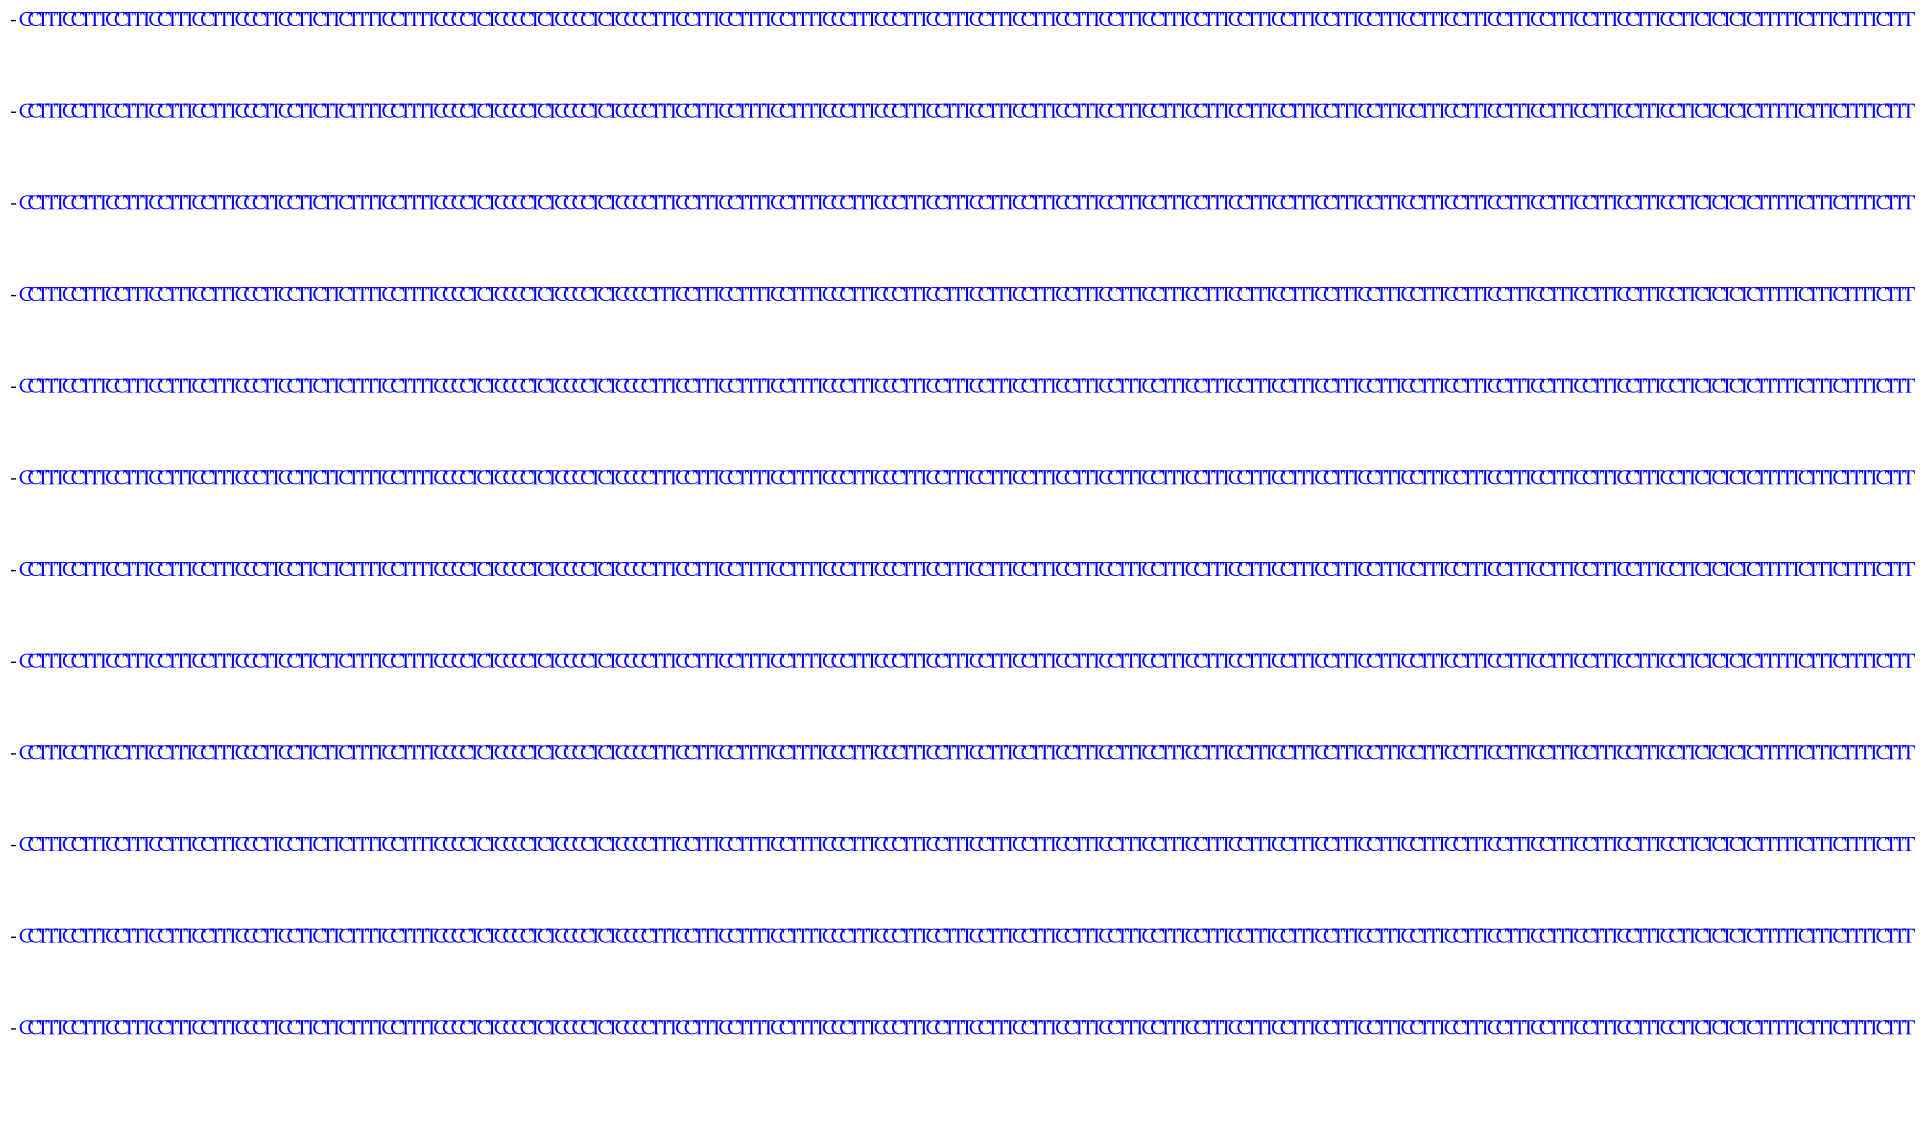

In [39]:
ani = animation.FuncAnimation(fig=fig, func=draw, frames=FRAMES*FPS//24, interval=1)

FFwriter = animation.FFMpegWriter(fps=FPS)
ani.save('animation.mp4', writer=FFwriter)
fig

In [40]:
from moviepy import VideoFileClip, clips_array

clip1 = VideoFileClip("original.mp4")
clip2 = VideoFileClip("animation.mp4")

final_clip = clips_array([[clip1, clip2]])

final_clip.write_videofile("final.mp4", fps=24)

MoviePy - Building video final.mp4.
MoviePy - Writing audio in finalTEMP_MPY_wvf_snd.mp3


MoviePy - Done.
MoviePy - Writing video final.mp4



frame_index: 100%|███████████████| 5259/5259 [16:35<00:00,  5.03it/s, now=None]/home/junyang/Desktop/blast-apple/venv/lib/python3.12/site-packages/moviepy/video/io/ffmpeg_reader.py:190: UserWarning: In file original.mp4, 518400 bytes wanted but 0 bytes read at frame index 6572 (out of a total 6574 frames), at time 219.07/219.15 sec. Using the last valid frame instead.
  warnings.warn(


MoviePy - Done !
MoviePy - video ready final.mp4


In [41]:
from IPython.display import Video
Video("final.mp4")

In [42]:
del ani
plt.close(fig)